# TransferVision-ML11 — Transfer Learning vs Fine-Tuning

This project compares:
1. **Feature extraction:** frozen ImageNet-pretrained ResNet18; train only the new classification head.
2. **Fine-tuning:** unfreeze ResNet18 `layer4` and the new head.
3. **CNN from scratch:** a small CNN without pretrained weights.

Dataset: three Oxford-IIIT Pet breeds — Abyssinian, Bengal, and Birman. The official image archive is about 792 MB. Keep a stable internet connection during the first download.

Run all cells in order. Accuracy and training times are computed from your actual runs; do not invent results.

In [1]:
from pathlib import Path
import time, tarfile, urllib.request, random, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_ROOT = ROOT / "data" / "oxford-iiit-pet"
IMAGE_DIR = DATA_ROOT / "images"
REPORTS = ROOT / "reports"
FIGURES = REPORTS / "figures"
MODELS = ROOT / "models"
for p in (IMAGE_DIR, FIGURES, MODELS): p.mkdir(parents=True, exist_ok=True)
print("Project:", ROOT.resolve())
print("Device:", DEVICE)

Project: C:\Users\madhu\OneDrive\Desktop\6 month internship program\TransferVision-ML11
Device: cpu


## 1. Download the image archive
The code reuses an existing archive and skips downloading when images are already extracted.

In [2]:
archive = DATA_ROOT / "images.tar.gz"
url = "https://www.robots.ox.ac.uk/~vgg/data/pets/data/images.tar.gz"

if not any(IMAGE_DIR.glob("*.jpg")):
    if not archive.exists() or archive.stat().st_size < 100_000_000:
        print("Downloading approximately 792 MB; please wait...")
        urllib.request.urlretrieve(url, archive)
    print("Extracting images...")
    with tarfile.open(archive, "r:gz") as tar:
        # Python's data filter prevents unsafe archive paths.
        tar.extractall(path=DATA_ROOT, filter="data")
print("Images found:", len(list(IMAGE_DIR.glob("*.jpg"))))

Extracting images...
Images found: 7390


## 2. Select three breeds and make stratified splits

In [3]:
CLASS_NAMES = ["Abyssinian", "Bengal", "Birman"]
class_to_idx = {name: i for i, name in enumerate(CLASS_NAMES)}
rows = []
for path in IMAGE_DIR.glob("*.jpg"):
    breed = path.stem.rsplit("_", 1)[0]
    if breed in class_to_idx:
        rows.append({"path": str(path), "class_name": breed, "label": class_to_idx[breed]})
df = pd.DataFrame(rows)
if df.empty or df["class_name"].nunique() != 3:
    raise RuntimeError("Could not find all 3 breeds. Check the extracted images folder and filenames.")
display(df["class_name"].value_counts())
train_df, temp_df = train_test_split(df, test_size=0.30, random_state=SEED, stratify=df["label"])
val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED, stratify=temp_df["label"])
train_df, val_df, test_df = [x.reset_index(drop=True) for x in (train_df, val_df, test_df)]
print(f"Train={len(train_df)}, validation={len(val_df)}, test={len(test_df)}")

class_name
Abyssinian    200
Bengal        200
Birman        200
Name: count, dtype: int64

Train=420, validation=90, test=90


## 3. Preprocessing and DataLoaders
ResNet input is resized to 224×224 and normalized with ImageNet mean/std. Augmentation is applied only to training images.

In [4]:
MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
BATCH_SIZE = 16
EPOCHS = 3  # Increase to 5+ if time and hardware allow.
train_tf = transforms.Compose([
    transforms.Resize((224,224)), transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10), transforms.ColorJitter(brightness=.1, contrast=.1),
    transforms.ToTensor(), transforms.Normalize(MEAN, STD)
])
eval_tf = transforms.Compose([
    transforms.Resize((224,224)), transforms.ToTensor(), transforms.Normalize(MEAN, STD)
])
class BreedDataset(Dataset):
    def __init__(self, frame, tfm):
        self.frame, self.tfm = frame.reset_index(drop=True), tfm
    def __len__(self): return len(self.frame)
    def __getitem__(self, i):
        row = self.frame.iloc[i]
        with Image.open(row.path) as im: image = im.convert("RGB")
        return self.tfm(image), int(row.label)

train_ds = BreedDataset(train_df, train_tf)
train_eval_ds = BreedDataset(train_df, eval_tf)
val_ds, test_ds = BreedDataset(val_df, eval_tf), BreedDataset(test_df, eval_tf)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
train_eval_loader = DataLoader(train_eval_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print("DataLoaders ready.")

DataLoaders ready.


## 4. Training utilities

In [5]:
def epoch_pass(model, loader, criterion, optimizer=None):
    is_train = optimizer is not None
    model.train(is_train)
    loss_sum = correct = count = 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        if is_train: optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(is_train):
            logits = model(x)
            loss = criterion(logits, y)
            if is_train:
                loss.backward()
                optimizer.step()
        loss_sum += loss.item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        count += y.size(0)
    return loss_sum / max(count, 1), correct / max(count, 1)

def fit(model, name, optimizer):
    model.to(DEVICE)
    criterion = nn.CrossEntropyLoss()
    hist = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    start = time.perf_counter()
    for ep in range(EPOCHS):
        tl, ta = epoch_pass(model, train_loader, criterion, optimizer)
        vl, va = epoch_pass(model, val_loader, criterion)
        for k, v in zip(hist, (tl, ta, vl, va)): hist[k].append(v)
        print(f"{name} | {ep+1}/{EPOCHS} | train loss={tl:.4f} acc={ta:.3f} | val loss={vl:.4f} acc={va:.3f}")
    return model, hist, time.perf_counter() - start

@torch.no_grad()
def get_predictions(model, loader):
    model.eval(); truth, preds = [], []
    for x, y in loader:
        preds.extend(model(x.to(DEVICE)).argmax(1).cpu().tolist())
        truth.extend(y.tolist())
    return np.array(truth), np.array(preds)

def save_curves(hist, title, filename):
    e = range(1, len(hist["train_loss"])+1)
    fig, ax = plt.subplots(1, 2, figsize=(11,4))
    ax[0].plot(e, hist["train_loss"], marker="o", label="Train")
    ax[0].plot(e, hist["val_loss"], marker="o", label="Validation")
    ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(e, hist["train_acc"], marker="o", label="Train")
    ax[1].plot(e, hist["val_acc"], marker="o", label="Validation")
    ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    fig.suptitle(title); fig.tight_layout()
    fig.savefig(FIGURES / filename, dpi=150, bbox_inches="tight")
    plt.show()

## 5. Experiment A — Feature extraction
Only the new final layer is trainable.

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\madhu/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100.0%


Feature extraction | 1/3 | train loss=0.7532 acc=0.695 | val loss=0.4546 acc=0.867
Feature extraction | 2/3 | train loss=0.4076 acc=0.886 | val loss=0.2870 acc=0.933
Feature extraction | 3/3 | train loss=0.3478 acc=0.898 | val loss=0.2083 acc=0.956


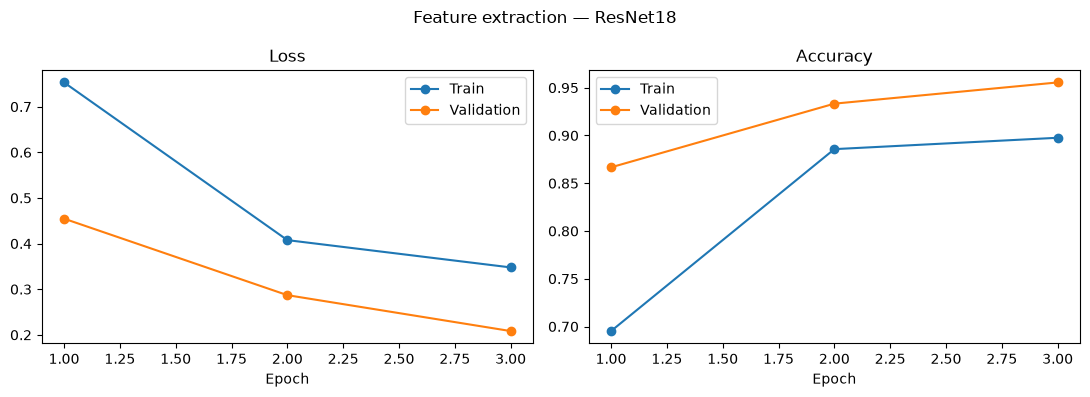

In [6]:
feature_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in feature_model.parameters(): p.requires_grad = False
feature_model.fc = nn.Linear(feature_model.fc.in_features, len(CLASS_NAMES))
feature_optimizer = torch.optim.Adam(feature_model.fc.parameters(), lr=1e-3)
feature_model, feature_hist, feature_seconds = fit(feature_model, "Feature extraction", feature_optimizer)
save_curves(feature_hist, "Feature extraction — ResNet18", "feature_extraction_curves.png")

## 6. Experiment B — Fine-tuning
Unfreeze `layer4` and the final classifier; use smaller learning rates.

Fine-tuning | 1/3 | train loss=0.3840 acc=0.843 | val loss=0.0864 acc=0.967
Fine-tuning | 2/3 | train loss=0.1817 acc=0.943 | val loss=0.0812 acc=0.967
Fine-tuning | 3/3 | train loss=0.0869 acc=0.969 | val loss=0.0798 acc=0.967


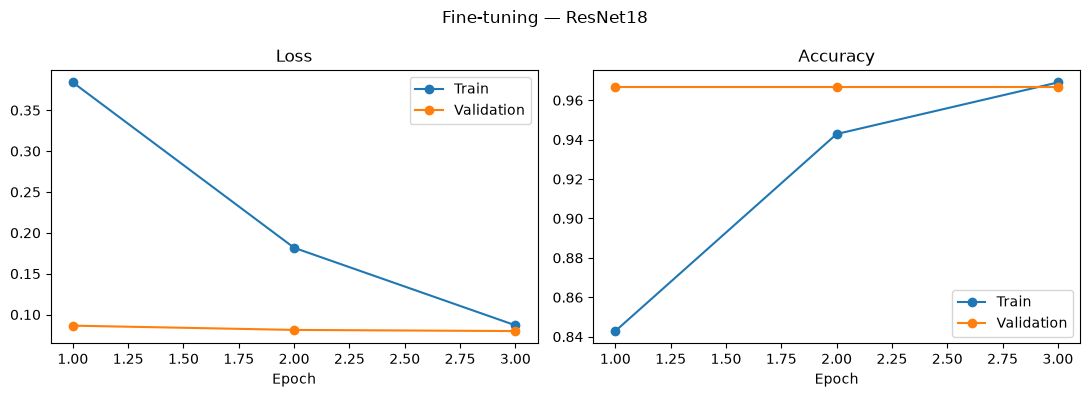

In [7]:
tune_model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in tune_model.parameters(): p.requires_grad = False
for p in tune_model.layer4.parameters(): p.requires_grad = True
tune_model.fc = nn.Linear(tune_model.fc.in_features, len(CLASS_NAMES))
tune_optimizer = torch.optim.Adam([
    {"params": tune_model.layer4.parameters(), "lr": 1e-4},
    {"params": tune_model.fc.parameters(), "lr": 5e-4}
])
tune_model, tune_hist, tune_seconds = fit(tune_model, "Fine-tuning", tune_optimizer)
save_curves(tune_hist, "Fine-tuning — ResNet18", "fine_tuning_curves.png")

## 7. Experiment C — CNN from scratch

CNN from scratch | 1/3 | train loss=1.0003 acc=0.521 | val loss=0.9879 acc=0.489
CNN from scratch | 2/3 | train loss=0.9451 acc=0.550 | val loss=0.9139 acc=0.578
CNN from scratch | 3/3 | train loss=0.8822 acc=0.619 | val loss=0.8428 acc=0.611


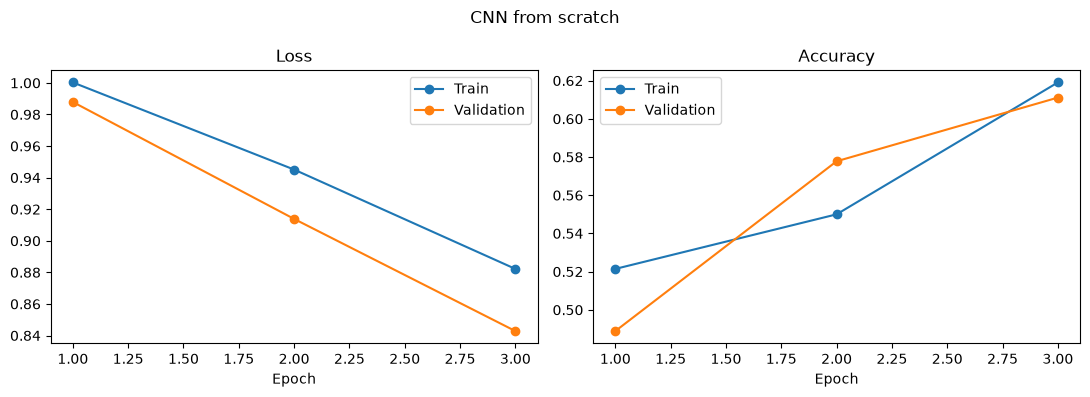

In [8]:
class ScratchCNN(nn.Module):
    def __init__(self, n=3):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3,32,3,padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32,64,3,padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(64,128,3,padding=1), nn.BatchNorm2d(128), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(128,192,3,padding=1), nn.BatchNorm2d(192), nn.ReLU(),
            nn.AdaptiveAvgPool2d((1,1))
        )
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(.3), nn.Linear(192,n))
    def forward(self,x): return self.head(self.features(x))

scratch_model = ScratchCNN(len(CLASS_NAMES))
scratch_optimizer = torch.optim.Adam(scratch_model.parameters(), lr=1e-3)
scratch_model, scratch_hist, scratch_seconds = fit(scratch_model, "CNN from scratch", scratch_optimizer)
save_curves(scratch_hist, "CNN from scratch", "scratch_cnn_curves.png")

## 8. Evaluate and compare on the held-out test set
The table is generated from the real run.


Feature extraction
              precision    recall  f1-score   support

  Abyssinian       1.00      0.93      0.97        30
      Bengal       0.94      1.00      0.97        30
      Birman       1.00      1.00      1.00        30

    accuracy                           0.98        90
   macro avg       0.98      0.98      0.98        90
weighted avg       0.98      0.98      0.98        90


Fine-tuning
              precision    recall  f1-score   support

  Abyssinian       0.96      0.87      0.91        30
      Bengal       0.88      0.97      0.92        30
      Birman       1.00      1.00      1.00        30

    accuracy                           0.94        90
   macro avg       0.95      0.94      0.94        90
weighted avg       0.95      0.94      0.94        90


CNN from scratch
              precision    recall  f1-score   support

  Abyssinian       0.47      0.63      0.54        30
      Bengal       0.77      0.57      0.65        30
      Birman       0.64 

,experiment,test_accuracy_percent,training_time_seconds,best_validation_accuracy_percent
0,Feature extraction,97.78,47.06,95.56
1,Fine-tuning,94.44,65.67,96.67
2,CNN from scratch,60.00,87.57,61.11


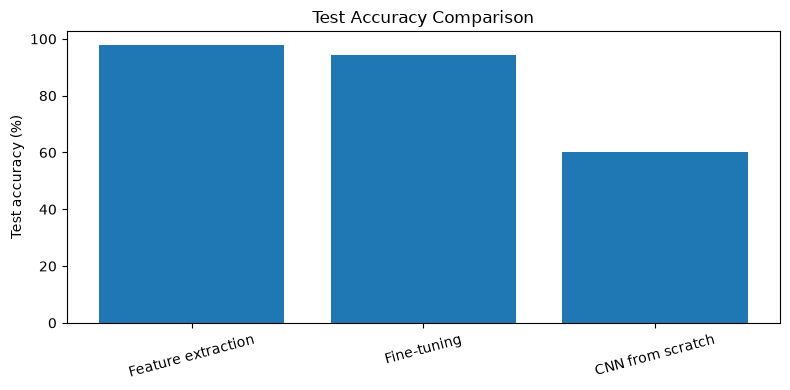

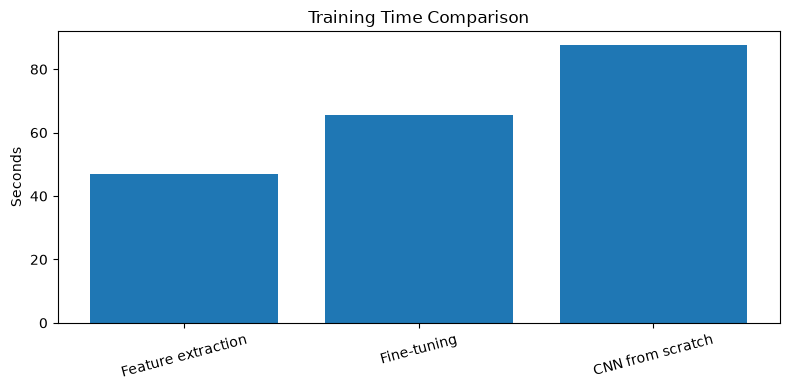

In [9]:
experiments = [
    ("Feature extraction", feature_model, feature_hist, feature_seconds),
    ("Fine-tuning", tune_model, tune_hist, tune_seconds),
    ("CNN from scratch", scratch_model, scratch_hist, scratch_seconds),
]
results = []
for name, model, hist, seconds in experiments:
    y_true, y_pred = get_predictions(model, test_loader)
    acc = accuracy_score(y_true, y_pred)
    results.append({
        "experiment": name,
        "test_accuracy_percent": round(acc*100, 2),
        "training_time_seconds": round(seconds, 2),
        "best_validation_accuracy_percent": round(max(hist["val_acc"])*100, 2)
    })
    print("\n" + name)
    print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, zero_division=0))

results_df = pd.DataFrame(results)
display(results_df)
REPORTS.mkdir(parents=True, exist_ok=True)
results_df.to_csv(REPORTS / "comparison_results.csv", index=False)

fig, ax = plt.subplots(figsize=(8,4))
ax.bar(results_df.experiment, results_df.test_accuracy_percent)
ax.set_ylabel("Test accuracy (%)"); ax.set_title("Test Accuracy Comparison")
ax.tick_params(axis="x", rotation=15); fig.tight_layout()
fig.savefig(FIGURES / "test_accuracy_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(8,4))
ax.bar(results_df.experiment, results_df.training_time_seconds)
ax.set_ylabel("Seconds"); ax.set_title("Training Time Comparison")
ax.tick_params(axis="x", rotation=15); fig.tight_layout()
fig.savefig(FIGURES / "training_time_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Save weights and summary

In [10]:
torch.save(feature_model.state_dict(), MODELS / "resnet18_feature_extraction.pth")
torch.save(tune_model.state_dict(), MODELS / "resnet18_finetuned.pth")
torch.save(scratch_model.state_dict(), MODELS / "scratch_cnn.pth")
summary = {
    "device": str(DEVICE),
    "classes": CLASS_NAMES,
    "epochs": EPOCHS,
    "batch_size": BATCH_SIZE,
    "results": results
}
with open(REPORTS / "experiment_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
print("Saved CSV, plots, summary, and model weights.")

Saved CSV, plots, summary, and model weights.


## Submission checklist
- Run every cell successfully and keep the generated comparison table and curves.
- Push notebook, README, and requirements to your public GitHub repository.
- Include actual results from your run; do not invent accuracy or timing.
- Discuss the accuracy/training-time trade-off between feature extraction, fine-tuning, and the scratch CNN.